# 04 · Selección del candidato y validación

**Pregunta:** ¿qué política se entrega y cómo sabemos que la mejora es real y no un artefacto de los escenarios sintéticos?
Esta libreta recorre (1) la comprobación de fidelidad del generador contra los datos reales, (2) la regla de selección fijada de antemano y su resultado,
(3) el control con los datos públicos reales y (4) la validación por conjuntos: afinado, decisión (HOLD), validación (FINAL) y datos frescos (FIN2).
Cada tabla sale de un CSV de `outputs/csvs/`.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # solucion/
REPO = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import plotstyle as PS, figs
PS.apply()
CSV, FIG = ROOT / "outputs" / "csvs", ROOT / "outputs" / "figs"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def show(fig):
    display(fig); plt.close(fig)

## 1 · Fidelidad del generador de escenarios frente a los datos reales
Los escenarios sintéticos se generan dentro de los rangos publicados. Antes de afinar se compara cada estadístico que la política podría explotar con los datos públicos.
El desfase de llegada entre las tarjetas de un mismo destino es uno de ellos: en los datos reales es uniforme entre 0 y 45 minutos desde la primera.

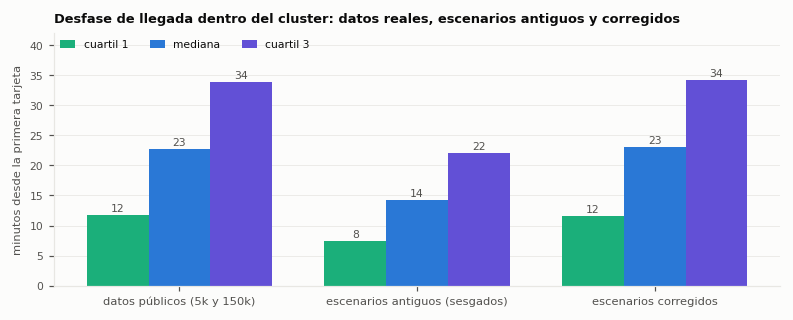

,version,coste,lead,lote_medio
0,candidato afinado con escenarios sesgados (top...,3676761,197.435,1.199
1,constantes de la 1.a corrida (tope 45 min),3593368,194.597,1.273


In [2]:
import matplotlib.pyplot as plt
bias = pd.read_csv(CSV/"evidencia_sesgo_generador.csv")
fig, ax = plt.subplots(figsize=(7.2, 2.9))
x = range(len(bias)); w = 0.26
for i, (col, lab, colr) in enumerate((("off_p25", "cuartil 1", PS.AQUA), ("off_p50", "mediana", PS.BLUE), ("off_p75", "cuartil 3", PS.VIOLET))):
    b = ax.bar([k + (i - 1) * w for k in x], bias[col], width=w, color=colr, label=lab)
    for r, v in zip(b, bias[col]): ax.text(r.get_x() + r.get_width()/2, v + 0.6, f"{v:.0f}", ha="center", fontsize=7, color=PS.INK2)
ax.set_ylim(0, 42); ax.set_xticks(list(x)); ax.set_xticklabels(bias.fuente, fontsize=7.5); ax.set_ylabel("minutos desde la primera tarjeta"); ax.legend(fontsize=7, frameon=False, ncol=3, loc="upper left")
ax.set_title("Desfase de llegada dentro del cluster: datos reales, escenarios antiguos y corregidos", fontsize=8.5, loc="left"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG/"fidelidad_generador.png"); show(fig)
pd.read_csv(CSV/"evidencia_sesgo_efecto_5k.csv")

El primer re-ajuste, hecho con los escenarios antiguos, eligió un tope de retención de 27,7 min que en el ejemplo público de 5 000 tarjetas empeoraba a la versión anterior
(tabla). Se corrigió el generador y se repitió el afinado; `fidelity_audit.py --gate` verifica los cuartiles antes de cada afinado.

## 2 · Regla de selección y resultado
Elegible: gates en HOLD, FINAL y los casos de contrato factibles, cero infracciones de retención y dominancia sobre el starter en las cuatro métricas en HOLD y FINAL.
Entre los elegibles se pide una **mejora robusta frente a la versión anterior** en puntos por percentil (intervalo bootstrap pareado con límite inferior mayor que cero);
si ninguno la logra, se conserva la versión anterior.

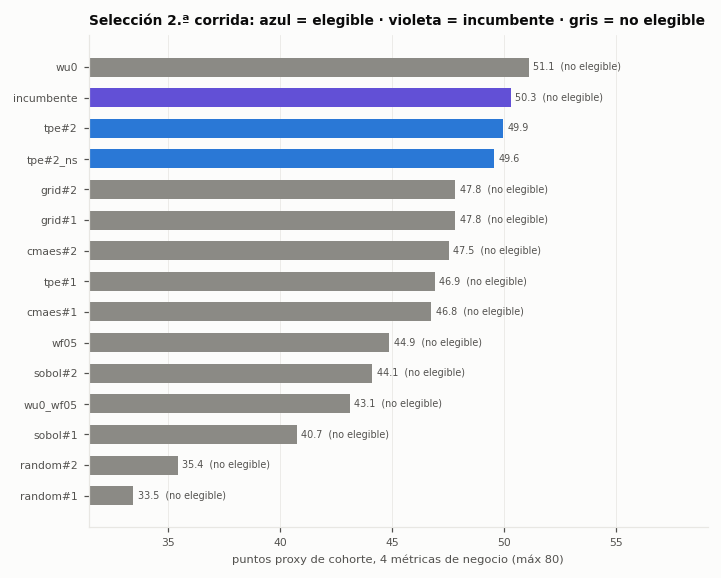

Con escenarios fieles a los datos reales (desfase de llegadas dentro del cluster ~ U(0, 45 min)) ningun candidato del re-ajuste supera de forma robusta (IC95 inferior > 0 en puntos por percentil) a las constantes de la 1.a corrida; se conservan, con el bucle de despacho corregido.


,candidato,Δ puntos por escenario,IC95 inferior,IC95 superior,gana en
11,wu0,0.81,-1.98,4.04,16/32
7,tpe#2,-0.36,-4.11,4.01,17/32
10,tpe#2_ns,-0.74,-4.58,3.60,16/32
0,grid#1,-2.48,-6.16,1.65,17/32
1,grid#2,-2.48,-6.16,1.67,17/32
9,cmaes#2,-2.76,-7.42,2.43,17/32
6,tpe#1,-3.37,-7.99,1.41,16/32
8,cmaes#1,-3.54,-7.30,0.34,14/32
12,wf05,-5.41,-8.57,-1.86,8/32
5,sobol#2,-6.17,-10.68,-1.54,11/32


In [3]:
sel = pd.read_csv(CSV/"v2_selection.csv"); dec = json.load(open(CSV/"v2_decision.json"))
show(figs.selection_proxy(sel))
rob = pd.DataFrame([{"candidato": k, "Δ puntos por escenario": round(v["dPuntos_medio"], 2), "IC95 inferior": round(v["IC95"][0], 2), "IC95 superior": round(v["IC95"][1], 2), "gana en": f"{v['gana_en']}/{v['n']}"}
                    for k, v in dec["robustez_puntos_vs_incumbente"].items()]).sort_values("Δ puntos por escenario", ascending=False)
print(dec["motivo"])
rob

## 3 · Control con los datos públicos reales
Los datos públicos no se usan para afinar; sirven de veto. El mejor candidato alternativo y la versión conservada se comparan con el starter en ambos ejemplos.

In [4]:
pc = pd.read_csv(CSV/"public_control.csv")
pc.round(3)

,scenario,candidate,status,unresolved,hold_breaches,sla_breach_rate,cost_total,lead_mean,lead_p95,rcp,avg_batch
0,public_5k,incumbente,COMPLETED,0,0,0.002,3593368,194.597,1523,9.965,1.273
1,public_5k,tpe#2_ns,COMPLETED,0,0,0.003,3605649,195.638,1523,9.959,1.258
2,public_5k,wu0,COMPLETED,0,0,0.003,3473416,200.972,1537,9.962,1.272
3,public_5k,starter,COMPLETED,16,42,0.007,4443213,230.555,1576,9.869,1.000
4,public_150k,incumbente,COMPLETED,0,0,0.004,111100128,193.478,1515,9.929,1.276
5,public_150k,tpe#2_ns,COMPLETED,0,0,0.004,110065684,192.330,1514,9.926,1.260
6,public_150k,wu0,COMPLETED,0,0,0.004,108637655,195.674,1515,9.929,1.276
7,public_150k,starter,COMPLETED,168,837,0.006,138126792,225.591,1565,9.876,1.000


## 4 · Validación por conjuntos (archivo final frente a starter y referencias simples)
`gana las 4` cuenta los escenarios donde la propuesta supera al starter en coste, tiempo medio, percentil 95 y satisfacción a la vez.

In [5]:
import v2data as V, robustness as R
d = V.load(); S = V.scen_sets(d)
allf = pd.concat([d[k].reset_index().assign(candidate=n) for k, n in (("final", "final_v2"), ("starter", "starter"), ("ref_price", "ref_price"), ("ref_eta", "ref_eta"), ("run1", "incumbente"))], ignore_index=True)
rows = []
for k, lab in (("tune", "Afinado"), ("hold", "HOLD"), ("final", "FINAL"), ("fin2", "FIN2")):
    names = S[k]; dm, dw = V.mean_delta(d["final"], d["starter"], names), V.dominance(d["final"], d["starter"], names)
    rows.append({"conjunto": lab, "escenarios": len(names), "gates": f"{sum(V.gate_ok(d['final'].loc[s]) for s in names)}/{len(names)}", "gates starter": f"{sum(V.gate_ok(d['starter'].loc[s]) for s in names)}/{len(names)}",
                 "retención": int(d["final"].loc[names].hold_breaches.sum()), "coste vs starter %": round(dm["coste_pct"], 1), "lead %": round(dm["lead_pct"], 1), "p95 %": round(dm["p95_pct"], 1),
                 "RCP Δ": round(dm["rcp_d"], 3), "gana las 4": f"{dw['todas']}/{len(names)}"})
tab = pd.DataFrame(rows); tab

,conjunto,escenarios,gates,gates starter,retención,coste vs starter %,lead %,p95 %,RCP Δ,gana las 4
0,Afinado,12,12/12,0/12,0,-19.4,-17.5,-4.6,0.136,12/12
1,HOLD,16,16/16,0/16,0,-21.0,-18.0,-6.7,0.171,16/16
2,FINAL,16,16/16,0/16,0,-22.3,-13.4,-3.6,0.136,15/16
3,FIN2,16,16/16,0/16,0,-20.3,-14.5,-4.2,0.136,16/16


### Datos frescos (FIN2): 16 escenarios que nunca intervinieron en el afinado

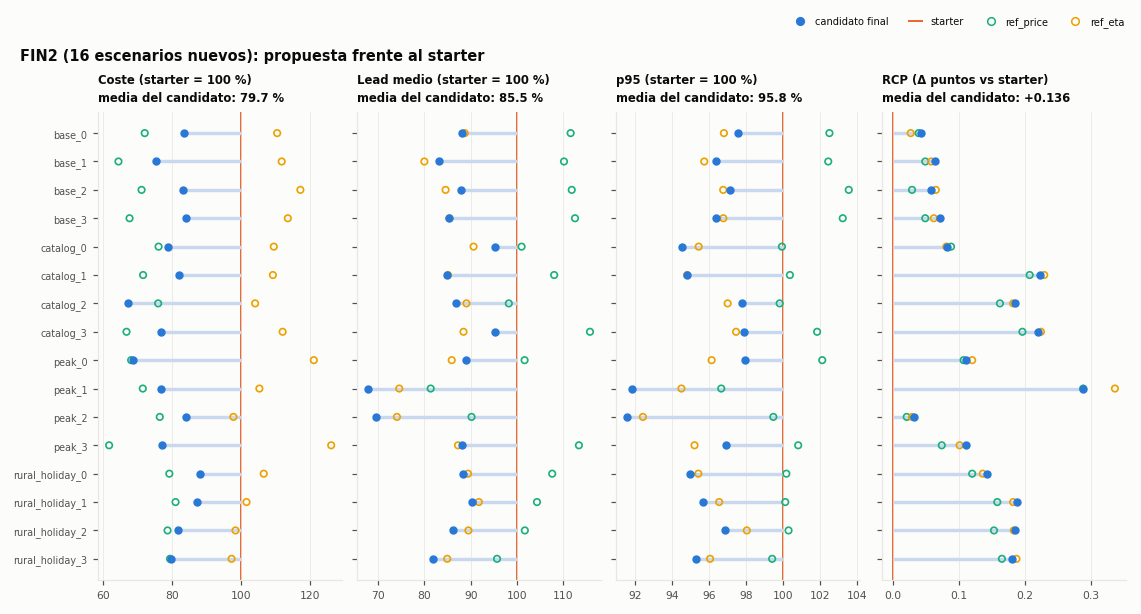

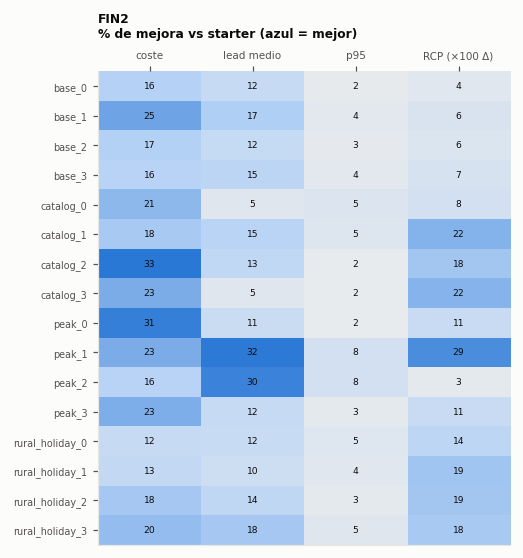

,candidato,gates,retención,UNRESOLVED,coste vs starter %,lead vs starter %,p95 vs starter %,RCP Δ,gana coste/lead/p95/RCP
0,final_v2,16/16,0,0,-20.3,-14.5,-4.2,0.136,16/16/16/16
1,incumbente,16/16,0,0,-20.3,-14.5,-4.2,0.136,16/16/16/16
2,ref_price,15/16,1,0,-27.3,4.0,0.8,0.119,16/4/5/16
3,ref_eta,16/16,0,0,8.9,-14.4,-4.1,0.138,3/16/16/16


In [6]:
names = S["fin2"]
show(figs.dumbbells(allf, names, "final_v2", "FIN2 (16 escenarios nuevos): propuesta frente al starter", "fin2_dumbbells.png", refs=("ref_price", "ref_eta")))
show(figs.improvement_heatmap(allf, names, "final_v2", "fin2_mejora_heatmap.png", "FIN2"))
st = allf[allf.candidate == "starter"].set_index("scenario").loc[names]
rows = []
for cand in ["final_v2", "incumbente", "ref_price", "ref_eta"]:
    g = allf[allf.candidate == cand].set_index("scenario").loc[names]
    rows.append({"candidato": cand, "gates": f"{sum(R.gate_ok(g.loc[s]) for s in names)}/{len(names)}", "retención": int(g.hold_breaches.sum()), "UNRESOLVED": int(g.unresolved.sum()),
                 "coste vs starter %": round(100*(g.cost_total/st.cost_total-1).mean(), 1), "lead vs starter %": round(100*(g.lead_mean/st.lead_mean-1).mean(), 1),
                 "p95 vs starter %": round(100*(g.lead_p95/st.lead_p95-1).mean(), 1), "RCP Δ": round((g.rcp-st.rcp).mean(), 3),
                 "gana coste/lead/p95/RCP": "/".join(str(int(x)) for x in [(g.cost_total<st.cost_total).sum(), (g.lead_mean<st.lead_mean).sum(), (g.lead_p95<st.lead_p95).sum(), (g.rcp>st.rcp).sum()])})
fin2_tab = pd.DataFrame(rows); fin2_tab.to_csv(CSV/"fin2_summary.csv", index=False); fin2_tab

### Decisión (HOLD) y validación (FINAL)

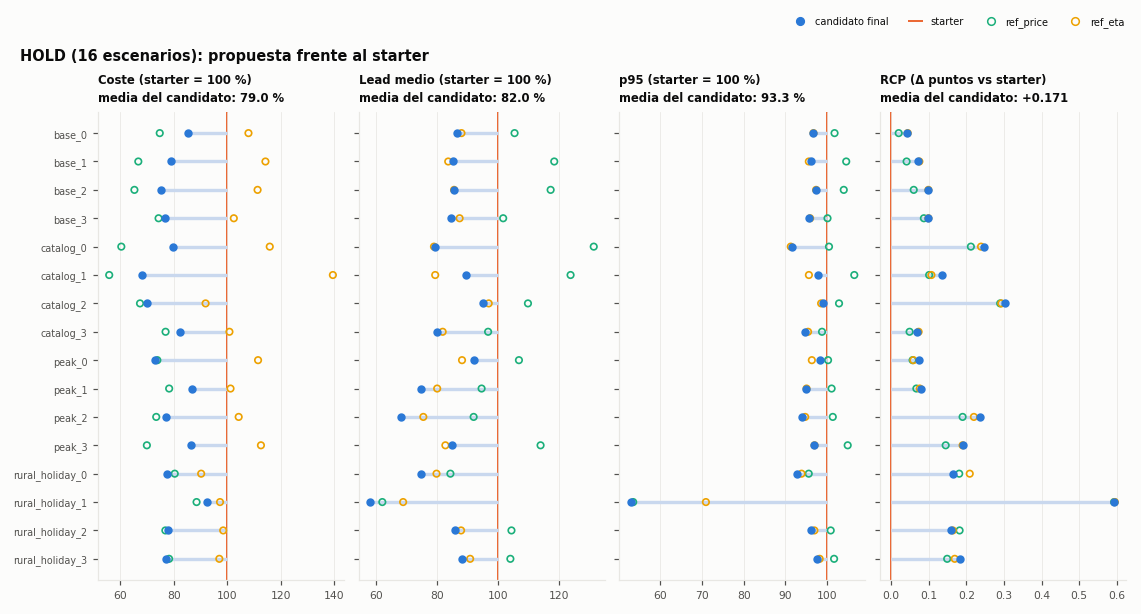

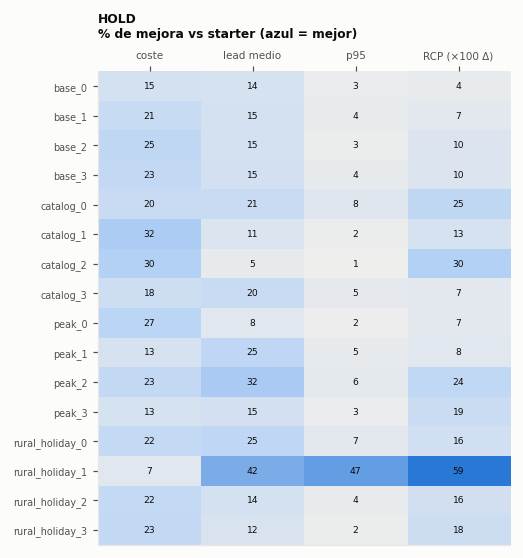

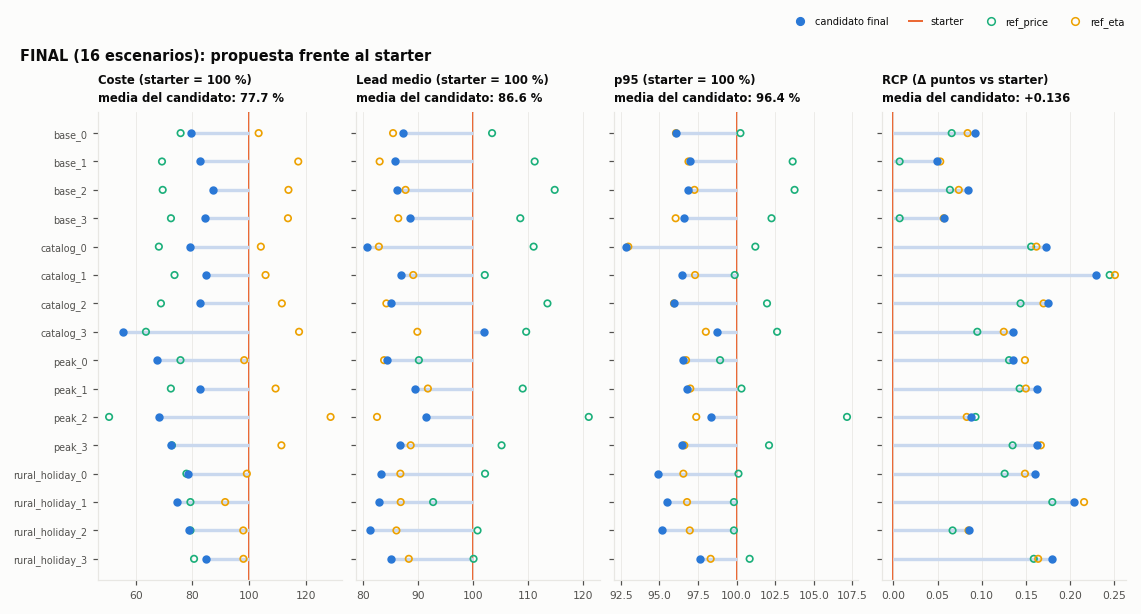

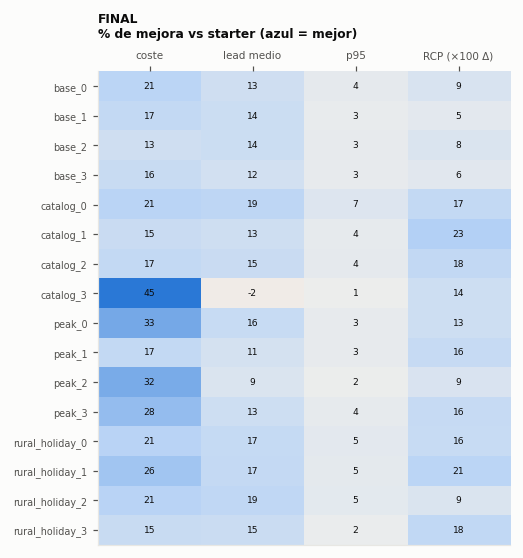

In [7]:
for k, lab in (("hold", "HOLD"), ("final", "FINAL")):
    show(figs.dumbbells(allf, S[k], "final_v2", f"{lab} ({len(S[k])} escenarios): propuesta frente al starter", f"validacion_{k}_dumbbells.png", refs=("ref_price", "ref_eta")))
    show(figs.improvement_heatmap(allf, S[k], "final_v2", f"validacion_{k}_heatmap.png", lab))

### Casos de contrato (extremos y estrés)
Se evalúan casos como ráfagas de 1 500 llegadas simultáneas, lotes de capacidad 1, flota al 30 %, un solo transportista, ids opacos y zonas sin cobertura.
Los que ninguna estrategia puede resolver (zona sin ningún transportista, envíos que exigen acceso difícil sin transportista que lo tenga, ráfaga mayor que la flota) se marcan aparte.

In [8]:
edge = d["final"].loc[S["edge"]][["status", "admitted", "unresolved", "sla_breach_rate", "hold_breaches", "cost_total", "lead_mean"]].copy()
edge["factible"] = [s not in V.INFEASIBLE for s in edge.index]
edge["gates"] = [V.gate_ok(d["final"].loc[s]) for s in edge.index]
edge.round(4)

,status,admitted,unresolved,sla_breach_rate,hold_breaches,cost_total,lead_mean,factible,gates
scenario,,,,,,,,,
edge_all_closed_sun_hol,COMPLETED,2500,0,0.0064,0,1930411,359.955,True,True
edge_burst_1500,COMPLETED,1500,0,0.0760,0,1362137,7758.839,False,False
edge_burst_bigfleet,COMPLETED,600,0,0.0067,0,377190,132.323,True,True
edge_cap1,COMPLETED,2500,0,0.0052,0,2091909,256.174,True,True
edge_empty,COMPLETED,0,0,0.0000,0,0,NaN,False,True
edge_no_hard_access,COMPLETED,2500,82,0.0412,0,2410887,258.280,False,False
edge_no_upgrades,COMPLETED,3000,0,0.0047,0,2001517,201.351,True,True
edge_one,COMPLETED,1,0,0.0000,0,1200,34.000,False,True
edge_opaque_ids,COMPLETED,3000,0,0.0063,0,2194159,218.948,True,True
